<a href="https://colab.research.google.com/github/ANANTHA1628/PCVK-Ganjil-26-27/blob/main/Week6_04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
NAMA = 'Aryaputra Ferdiananta'
NIM = '244107020127'
print(NAMA, NIM)

Aryaputra Ferdiananta 244107020127


In [9]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
import math
from google.colab.patches import cv2_imshow
from PIL import Image as im

In [ ]:
def convolution2d(image, kernel, stride=1, padding=0):
    kernel = np.flipud(np.fliplr(kernel))

    img_h, img_w = image.shape
    k_h, k_w = kernel.shape

    if padding > 0:
        padded = np.pad(image, pad_width=padding, mode='constant', constant_values=0)
    else:
        padded = image.copy()

    out_h = int(((img_h - k_h + 2 * padding) / stride) + 1)
    out_w = int(((img_w - k_w + 2 * padding) / stride) + 1)

    output = np.zeros((out_h, out_w), dtype=np.float32)
    for i in range(out_h):
        for j in range(out_w):
            r_start = i * stride
            r_end = r_start + k_h
            c_start = j * stride
            c_end = c_start + k_w

            roi = padded[r_start:r_end, c_start:c_end]
            output[i, j] = np.sum(roi * kernel)

    output = np.clip(output, 0, 255).astype(np.uint8)
    return output

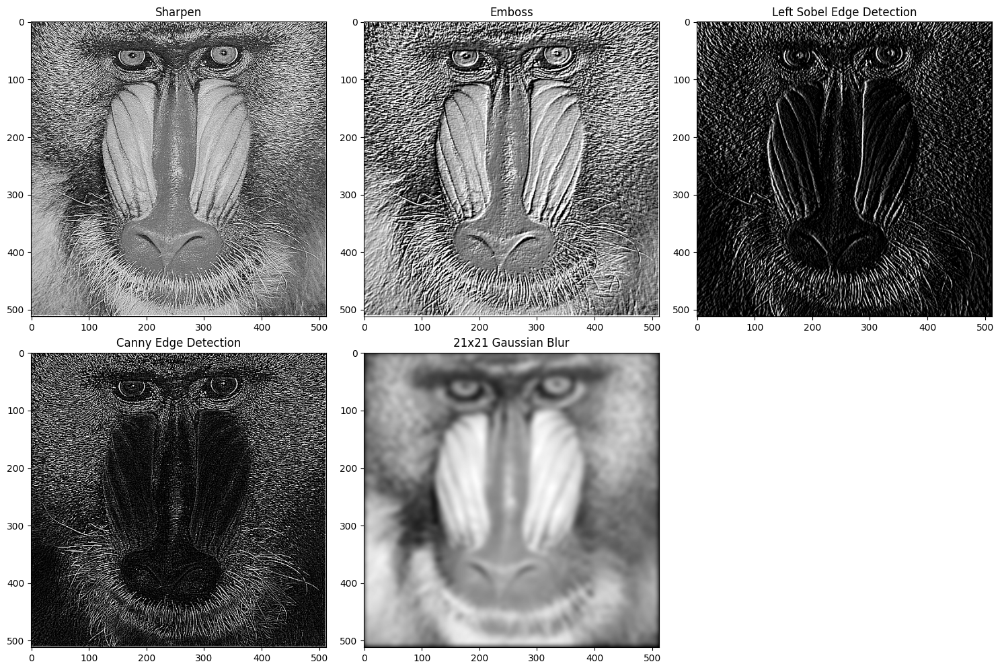

In [ ]:
img = cv.imread('/content/drive/MyDrive/mobile/mandrill.tiff')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

kernel_sharpen = np.array([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
], dtype=np.float32)

kernel_emboss = np.array([
    [-2, -1,  0],
    [-1,  1,  1],
    [ 0,  1,  2]
], dtype=np.float32)

kernel_left_sobel = np.array([
    [ 1,  0, -1],
    [ 2,  0, -2],
    [ 1,  0, -1]
], dtype=np.float32)

kernel_canny = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
], dtype=np.float32)

kernel_size = 21
sigma = math.sqrt(kernel_size)
gaussian_1d = cv.getGaussianKernel(kernel_size, sigma)
kernel_gaussian21 = gaussian_1d @ gaussian_1d.transpose()

res_sharpen = convolution2d(img_gray, kernel_sharpen, stride=1, padding=1)
res_emboss  = convolution2d(img_gray, kernel_emboss, stride=1, padding=1)
res_sobel   = convolution2d(img_gray, kernel_left_sobel, stride=1, padding=1)
res_canny   = convolution2d(img_gray, kernel_canny, stride=1, padding=1)
res_gauss21 = convolution2d(img_gray, kernel_gaussian21, stride=1, padding=10)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes[0, 0].imshow(res_sharpen, cmap='gray'); axes[0, 0].set_title('Sharpen')
axes[0, 1].imshow(res_emboss, cmap='gray'); axes[0, 1].set_title('Emboss')
axes[0, 2].imshow(res_sobel, cmap='gray'); axes[0, 2].set_title('Left Sobel Edge Detection')
axes[1, 0].imshow(res_canny, cmap='gray'); axes[1, 0].set_title('Canny Edge Detection')
axes[1, 1].imshow(res_gauss21, cmap='gray'); axes[1, 1].set_title('21x21 Gaussian Blur')
axes[1, 2].axis('off')

for ax in axes.flat:
    if ax.has_data():
        ax.axis('on')
plt.tight_layout()
plt.show()

In [ ]:
def show_side_by_side(images, titles, figsize=(15, 5)):
    plt.figure(figsize=figsize)
    for i, (image_item, title) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i + 1)
        if len(image_item.shape) == 2:
            plt.imshow(image_item, cmap="gray")
        else:
            plt.imshow(cv.cvtColor(image_item, cv.COLOR_BGR2RGB))
        plt.title(title)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

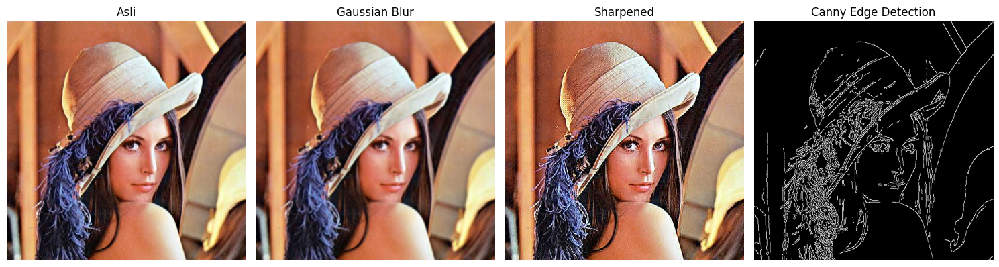

In [ ]:
img_lena = cv.imread('/content/drive/MyDrive/mobile/lena.jpg')
blur = cv.GaussianBlur(img_lena, (7, 7), 1)
edges = cv.Canny(cv.cvtColor(img_lena, cv.COLOR_BGR2GRAY), 100, 200)
sharpen_kernel = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])
sharpened = cv.filter2D(img_lena, -1, sharpen_kernel)

show_side_by_side([img_lena, blur, sharpened, edges],
                   ["Asli", "Gaussian Blur", "Sharpened", "Canny Edge Detection"])

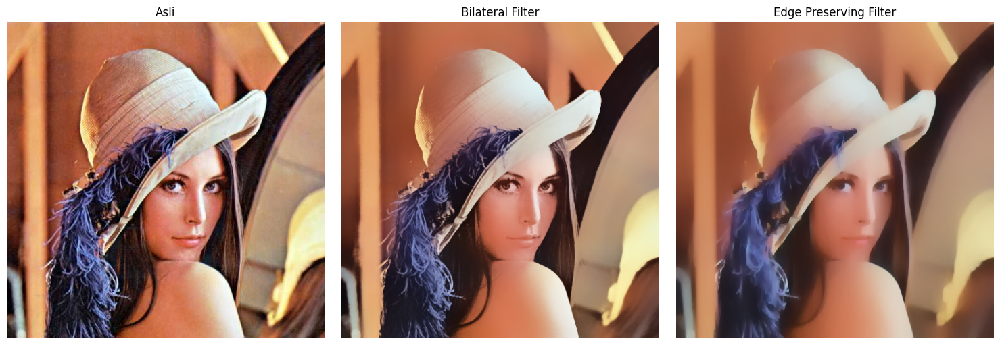

In [ ]:
bilateral = cv.bilateralFilter(img_lena, 50, 100, 100)
edge_preserve = cv.edgePreservingFilter(img_lena, flags=1, sigma_s=100, sigma_r=0.9)

show_side_by_side([img_lena, bilateral, edge_preserve],
                   ["Asli", "Bilateral Filter", "Edge Preserving Filter"])

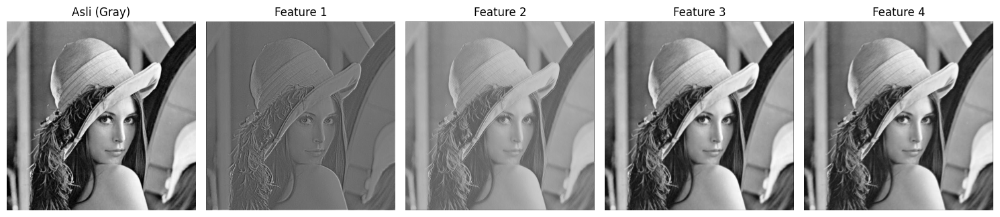

In [ ]:
import torch
import torch.nn as nn

class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 4, kernel_size=3, stride=1, padding=1)

    def forward(self, x):
        return self.conv1(x)

model = SimpleCNN()
img_gray_lena = cv.cvtColor(img_lena, cv.COLOR_BGR2GRAY)
img_tensor = torch.tensor(img_gray_lena, dtype=torch.float32).unsqueeze(0).unsqueeze(0) / 255.0

with torch.no_grad():
    features = model(img_tensor)

feature_maps = [features[0, i].numpy() for i in range(features.shape[1])]
show_side_by_side([img_gray_lena] + feature_maps,
                   ["Asli (Gray)"] + [f"Feature {i+1}" for i in range(len(feature_maps))])

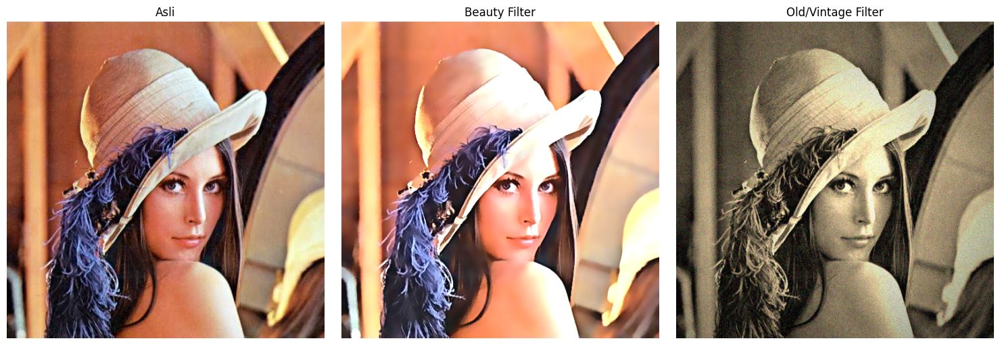

In [ ]:
# 1. Beauty Filter
smooth = cv.bilateralFilter(img_lena, d=15, sigmaColor=75, sigmaSpace=75)
gaussian = cv.GaussianBlur(smooth, (0, 0), 3)
sharpened_b = cv.addWeighted(smooth, 1.5, gaussian, -0.5, 0)
beauty = cv.convertScaleAbs(sharpened_b, alpha=1.2, beta=15)

# 2. Old/Vintage Filter
sepia_kernel = np.array([
    [0.272, 0.534, 0.131],
    [0.349, 0.686, 0.168],
    [0.393, 0.769, 0.189]
])
sepia = cv.transform(img_lena, sepia_kernel)
sepia = np.clip(sepia, 0, 255).astype(np.uint8)

rows, cols = img_lena.shape[:2]
kernel_x = cv.getGaussianKernel(cols, cols * 0.6)
kernel_y = cv.getGaussianKernel(rows, rows * 0.6)
kernel_vignette = kernel_y * kernel_x.T
mask_vignette = kernel_vignette / kernel_vignette.max()

vignette = np.copy(sepia)
for i in range(3):
    vignette[:, :, i] = vignette[:, :, i] * mask_vignette

noise = np.random.normal(0, 15, vignette.shape).astype(np.int16)
old_img = np.clip(vignette.astype(np.int16) + noise, 0, 255).astype(np.uint8)

show_side_by_side([img_lena, beauty, old_img], ["Asli", "Beauty Filter", "Old/Vintage Filter"])

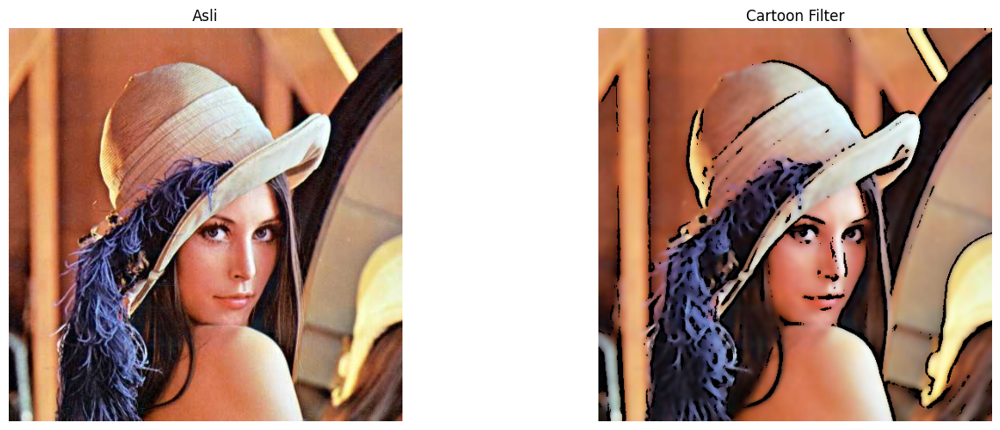

In [ ]:
gray = cv.cvtColor(img_lena, cv.COLOR_BGR2GRAY)
gray_blur = cv.medianBlur(gray, 7)
edges = cv.adaptiveThreshold(gray_blur, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, 9, 9)
color = cv.bilateralFilter(img_lena, d=9, sigmaColor=200, sigmaSpace=200)
cartoon = cv.bitwise_and(color, color, mask=edges)

show_side_by_side([img_lena, cartoon], ["Asli", "Cartoon Filter"])

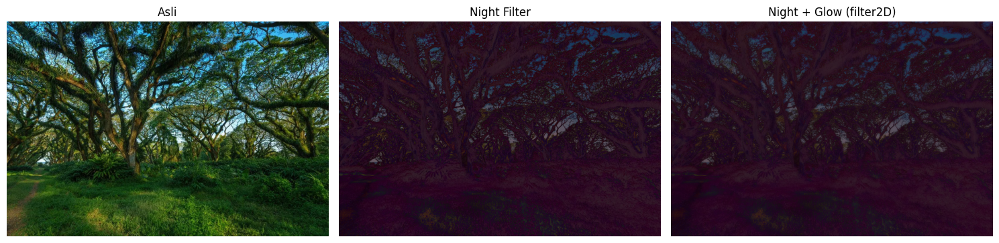

In [ ]:
img_djawatan = cv.imread("/content/drive/MyDrive/mobile/djawatan.jpg")

night = cv.convertScaleAbs(img_djawatan, alpha=0.6, beta=-40)

blue_tint = np.full_like(night, (50, 0, 100)) # Format BGR
night = cv.addWeighted(night, 0.8, blue_tint, 0.2, 0)

kernel = np.ones((15, 15), np.float32) / 225
glow = cv.filter2D(night, -1, kernel)

night_glow = cv.addWeighted(night, 0.7, glow, 0.3, 0)

show_side_by_side([img_djawatan, night, night_glow],
                   ["Asli", "Night Filter", "Night + Glow (filter2D)"])

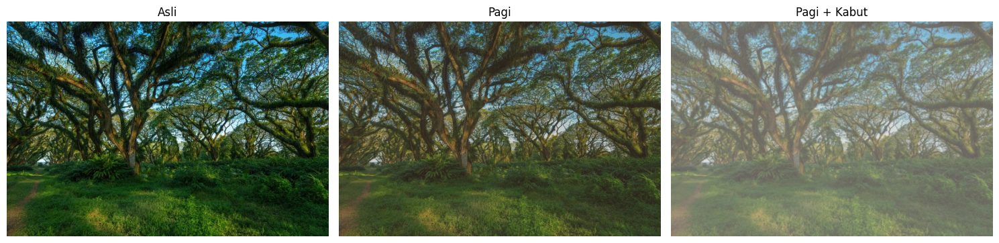

In [ ]:
img_djawatan = cv.imread("/content/drive/MyDrive/mobile/djawatan.jpg")

# Step 1: Kurangi kontras & cerahkan
alpha = 0.9  # Contrast
beta = 20    # Brightness
soft = cv.convertScaleAbs(img_djawatan, alpha=alpha, beta=beta)

# Step 2: Tambahkan warm tone (kemerahan / oranye)
warm_tint = np.full_like(soft, (40, 70, 120)) # Format BGR
pagi = cv.addWeighted(soft, 0.8, warm_tint, 0.2, 0)

# Step 3: Tambahkan haze (kabut tipis) dengan filter2D menggunakan kernel Gaussian 2D
kernel = cv.getGaussianKernel(3, 3)
kernel = kernel @ kernel.T # Matriks 2D
kabut = cv.filter2D(pagi, -1, kernel)

# Step 4: Tambahkan layer putih untuk efek kabut yang lebih nyata
white_layer = np.full_like(pagi, 255)
kabut = cv.addWeighted(kabut, 0.7, white_layer, 0.3, 0)

# Tampilkan hasil Percobaan 7
show_side_by_side([img_djawatan, pagi, kabut],
                   ["Asli", "Pagi", "Pagi + Kabut"])

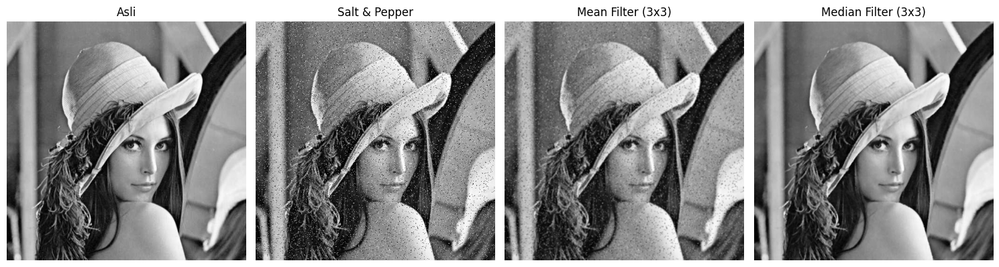

In [13]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import os
import urllib.request

def show_side_by_side(images, titles, figsize=(15, 5)):
    plt.figure(figsize=figsize)
    for i, (image_item, title) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i + 1)
        if len(image_item.shape) == 2:
            plt.imshow(image_item, cmap="gray")
        else:
            plt.imshow(cv.cvtColor(image_item, cv.COLOR_BGR2RGB))
        plt.title(title)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

def add_salt_and_pepper_noise(image, salt_prob=0.02, pepper_prob=0.02):
    noisy = image.copy()
    num_salt = np.ceil(salt_prob * image.size)
    coords = [np.random.randint(0, i - 1, int(num_salt)) for i in image.shape]
    noisy[tuple(coords)] = 255

    num_pepper = np.ceil(pepper_prob * image.size)
    coords = [np.random.randint(0, i - 1, int(num_pepper)) for i in image.shape]
    noisy[tuple(coords)] = 0
    return noisy

path_lena = '/content/drive/MyDrive/mobile/lena.jpg'
img_lena = cv.imread(path_lena)
img_gray_lena = cv.cvtColor(img_lena, cv.COLOR_BGR2GRAY)

noisy_img = add_salt_and_pepper_noise(img_gray_lena, 0.03, 0.03)

mean_filtered = cv.blur(noisy_img, (3, 3))
median_filtered = cv.medianBlur(noisy_img, 3)

show_side_by_side([img_gray_lena, noisy_img, mean_filtered, median_filtered],
                   ["Asli", "Salt & Pepper", "Mean Filter (3x3)", "Median Filter (3x3)"])

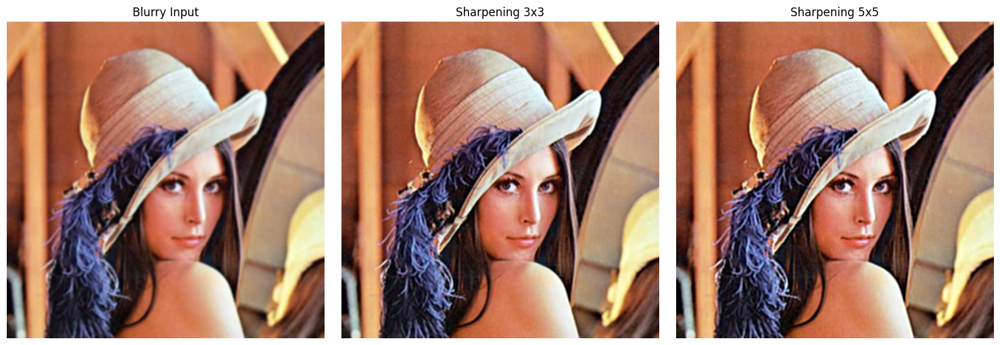

In [11]:
kernel_sharp_3x3 = np.array([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
], dtype=np.float32)

kernel_sharp_5x5 = np.array([
    [-1, -1, -1, -1, -1],
    [-1,  2,  2,  2, -1],
    [-1,  2,  8,  2, -1],
    [-1,  2,  2,  2, -1],
    [-1, -1, -1, -1, -1]
], dtype=np.float32) / 8.0

blurry_input = cv.GaussianBlur(img_lena, (5, 5), 1.5)

res_sharp_3x3 = cv.filter2D(blurry_input, -1, kernel_sharp_3x3)
res_sharp_5x5 = cv.filter2D(blurry_input, -1, kernel_sharp_5x5)

show_side_by_side([blurry_input, res_sharp_3x3, res_sharp_5x5],
                   ["Blurry Input", "Sharpening 3x3", "Sharpening 5x5"])

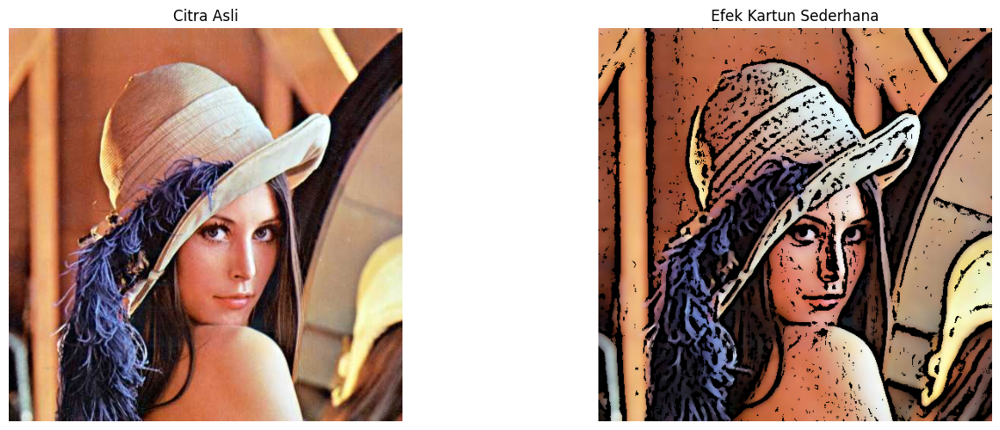

In [12]:
def kartun(image):
    color = cv.bilateralFilter(image, d=9, sigmaColor=150, sigmaSpace=150)

    gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
    blurred_gray = cv.medianBlur(gray, 7)
    edges = cv.adaptiveThreshold(
        blurred_gray, 255,
        cv.ADAPTIVE_THRESH_MEAN_C,
        cv.THRESH_BINARY,
        blockSize=9,
        C=2
    )

    edges_colored = cv.cvtColor(edges, cv.COLOR_GRAY2BGR)

    cartoon_img = cv.bitwise_and(color, edges_colored)
    return cartoon_img

hasil_kartun = kartun(img_lena)
show_side_by_side([img_lena, hasil_kartun], ["Citra Asli", "Efek Kartun Sederhana"])